In [1]:
import numpy as np
import pandas as pd
import scipy.optimize
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
from scipy.signal import find_peaks
import math
import pyperclip


Import Data and Filter t range

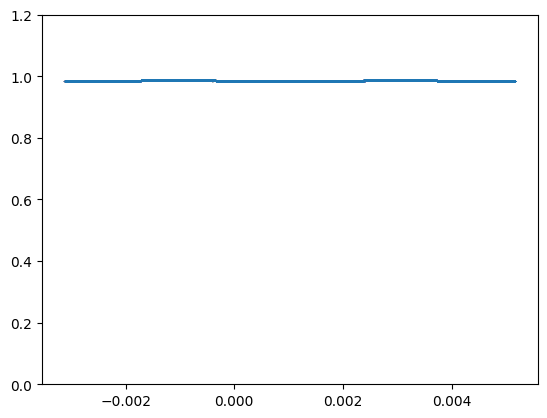

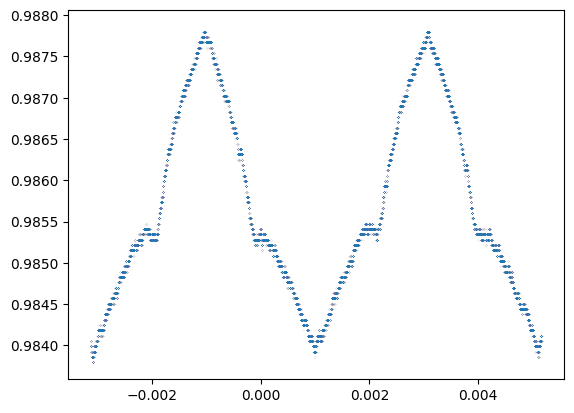

In [6]:
filepath = "absorption_data/data_112825/flux_data/450 raw0.csv"
data = pd.read_csv(filepath)

t = data['Time(s)']
CH2 = data["CH2(V)"]

plt.plot(t,CH2, markersize = 0.005, linestyle = "None", marker = ".")
plt.ylim(0,1.2)
plt.show()

plt.plot(t,CH2, markersize = 0.005, linestyle = "None", marker = ".")

In [18]:
filepath = "absorption_data/data_112825/475.csv"

# #select side n,1,2,3, or 4
side = "3"

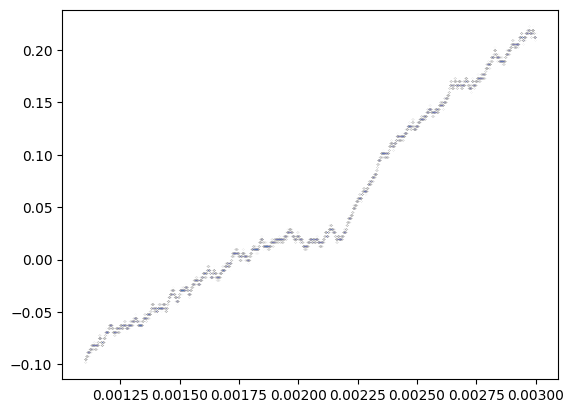

In [19]:
#filepath = "475.csv"

# #select side n,1,2,3, or 4
#side = "3"

data = pd.read_csv(filepath)


# Set t range to cut off when ramp flips direction
t_min, t_max = -np.inf, np.inf
if side == "n":
    t_min, t_max = -np.inf, np.inf
elif side == "1":
    t_min, t_max = -0.003, -0.00105
elif side =="2":
    t_min, t_max = -0.0009, 0.001
elif side =="3":
    t_min, t_max = 0.0011, 0.003
elif side == "4":
    t_min, t_max = 0.0031, 0.005

data_filtered = data[(data['Time(s)'] >= t_min) & (data['Time(s)'] <= t_max)]

t = data_filtered['Time(s)']
CH2 = data_filtered["CH2(V)"]

plt.plot(t,CH2, markersize = 0.005, linestyle = "None", marker = ".")

0.004160857487014172


<function matplotlib.pyplot.show(close=None, block=None)>

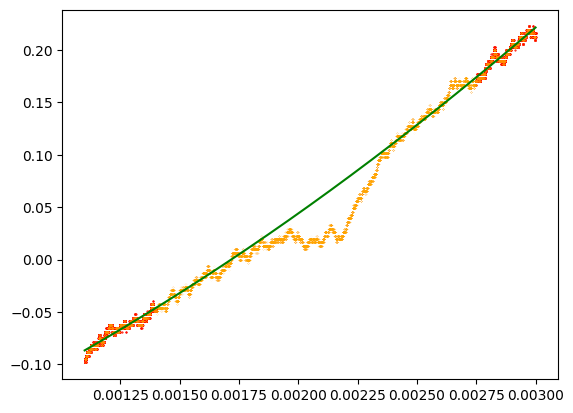

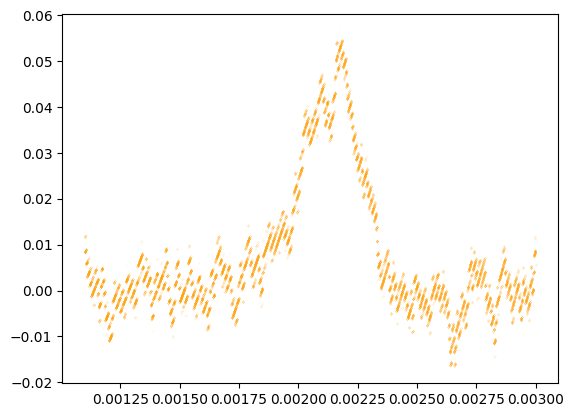

In [33]:
#filter data to not include the peaks 

if side == "1":
    t_remove_min, t_remove_max = -0.00275, -0.0013
elif side == "2":
    t_remove_min, t_remove_max = -0.0007, 0.00075
elif side == "3":
    t_remove_min, t_remove_max = 0.0014, 0.00275
elif side == "4":
    t_remove_min, t_remove_max = 0.0033, 0.00475

data_subtrac_ramp = data_filtered[(data_filtered['Time(s)'] < t_remove_min) | (data_filtered['Time(s)'] > t_remove_max)]

t_ramp = data_subtrac_ramp['Time(s)']
CH2_ramp = data_subtrac_ramp["CH2(V)"]

#do polynomial fit
coeffs = np.polyfit(t_ramp,CH2_ramp, deg = 2)
ramp = np.polyval(coeffs,t)

#get estimate for noise error
resid = CH2_ramp - np.polyval(coeffs,t_ramp)
dof = len(t_ramp) - 3 #quadratic fit
sigma_y = np.sqrt(np.sum(resid**2)/dof) #rms noise
print(sigma_y)

plt.figure()
plt.plot(t_ramp,CH2_ramp, markersize = 1, linestyle = "None", marker = ".", color='red')
plt.plot(t,CH2, markersize = 0.05, linestyle = "None", marker = ".",color = "orange")
plt.plot(t,ramp,color='green')
plt.show

# subtract the ramp from data

Rb_spectrum = - (CH2 - ramp)
plt.figure()
plt.plot(t, Rb_spectrum, markersize = 0.05, linestyle = "None", marker = ".", color = "orange")
plt.show

0.05149692624094269,8.400479001802724e-05


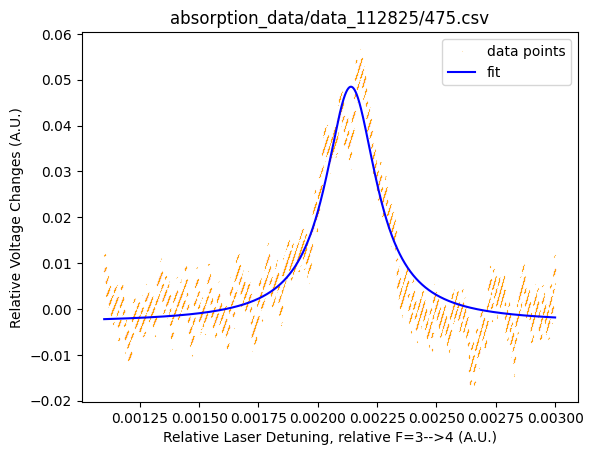

In [21]:
#def lorentzian 
def lorentz(x,G):
    return 1.0 / (1.0 + (x / (G/2.0))**2)

def model_function(x,G,scale,dx,offset):
    return scale*lorentz(x-dx,G)+offset

# initial guesses
if side == "1":
    dx_guess = -0.00185
elif side == "2":
    dx_guess = -0.0002
elif side =="3":
    dx_guess = 0.00225
elif side =="4":
    dx_guess = 0.0039

H_guess = np.nanmax(Rb_spectrum) - np.nanmedian(Rb_spectrum)  # rough

p0 = [2.0e-4, H_guess, dx_guess, 0.0]
lb = [1e-12, 0.0, -np.inf, -np.inf]  # G>0, H>=0
ub = [9.5e-3,  np.inf,  np.inf,  np.inf]

popt, pcov = curve_fit(
    model_function, t, Rb_spectrum,
    p0=p0, sigma=sigma_y, absolute_sigma=True,
    bounds=(lb, ub), method="trf", maxfev= 1000
)


#get fits
G, scale, dx,offset = popt
eG, escale,edx,eoffset = np.sqrt(np.diag(pcov))

# create best fit data
y_fit = model_function(t, *popt)

# get reduced chi^2
residual = Rb_spectrum - y_fit
chi_squared = np.sum((residual / sigma_y) ** 2)
dof = len(t) - len(popt)
chi_squared_reduced = chi_squared / dof

fig, ax = plt.subplots()
ax.plot(t, Rb_spectrum, markersize = 0.05, linestyle = "None", marker = "x",color = "orange", label = "data points")
ax.plot(t,y_fit, label ="fit", color = "blue")
ax.set_xlabel("Relative Laser Detuning, relative F=3-->4 (A.U.)")
ax.set_ylabel("Relative Voltage Changes (A.U.)")
ax.set_title(filepath)
ax.legend(loc='best')


pyperclip.copy(f"{scale},")
print(f"{scale},{escale}")

In [ ]:
# ── BATCH RUNNER ─────────────────────────────────────────────────────────────
# Runs the fit for every height × side combination and saves results to CSV.
# All logic below is copied verbatim from your existing cells (4-6).

heights = [100, 200, 300, 350, 400, 425, 450, 475, 500, 550, 600, 700, 800, 900]
sides   = ["1", "2", "3", "4"]

results = []  # list of dicts, one per height

for height in heights:
    filepath = f"absorption_data/data_112825/{height}.csv"
    row = {"height": height}

    for side in sides:
        try:
            # ── Cell 4 logic ────────────────────────────────────────────────────
            data = pd.read_csv(filepath)

            t_min, t_max = -np.inf, np.inf
            if side == "n":
                t_min, t_max = -np.inf, np.inf
            elif side == "1":
                t_min, t_max = -0.003, -0.00105
            elif side == "2":
                t_min, t_max = -0.0009, 0.001
            elif side == "3":
                t_min, t_max = 0.0011, 0.003
            elif side == "4":
                t_min, t_max = 0.0031, 0.005

            data_filtered = data[(data['Time(s)'] >= t_min) & (data['Time(s)'] <= t_max)]
            t   = data_filtered['Time(s)']
            CH2 = data_filtered["CH2(V)"]

            # ── Cell 5 logic ────────────────────────────────────────────────────
            if side == "1":
                t_remove_min, t_remove_max = -0.00275, -0.0013
            elif side == "2":
                t_remove_min, t_remove_max = -0.0007, 0.00075
            elif side == "3":
                t_remove_min, t_remove_max = 0.0014, 0.00275
            elif side == "4":
                t_remove_min, t_remove_max = 0.0033, 0.00475

            data_subtrac_ramp = data_filtered[
                (data_filtered['Time(s)'] < t_remove_min) |
                (data_filtered['Time(s)'] > t_remove_max)
            ]
            t_ramp   = data_subtrac_ramp['Time(s)']
            CH2_ramp = data_subtrac_ramp["CH2(V)"]

            coeffs = np.polyfit(t_ramp, CH2_ramp, deg=2)
            ramp   = np.polyval(coeffs, t)

            resid   = CH2_ramp - np.polyval(coeffs, t_ramp)
            dof_r   = len(t_ramp) - 3
            sigma_y = np.sqrt(np.sum(resid**2) / dof_r)

            Rb_spectrum = -(CH2 - ramp)

            # ── Cell 6 logic ────────────────────────────────────────────────────
            def lorentz(x, G):
                return 1.0 / (1.0 + (x / (G / 2.0))**2)

            def model_function(x, G, scale, dx, offset):
                return scale * lorentz(x - dx, G) + offset

            if side == "1":
                dx_guess = -0.00185
            elif side == "2":
                dx_guess = -0.0002
            elif side == "3":
                dx_guess = 0.00225
            elif side == "4":
                dx_guess = 0.0039

            H_guess = np.nanmax(Rb_spectrum) - np.nanmedian(Rb_spectrum)
            p0 = [2.0e-4, H_guess, dx_guess, 0.0]
            lb = [1e-12, 0.0, -np.inf, -np.inf]
            ub = [9.5e-3,  np.inf,  np.inf,  np.inf]

            popt, pcov = curve_fit(
                model_function, t, Rb_spectrum,
                p0=p0, sigma=sigma_y, absolute_sigma=True,
                bounds=(lb, ub), method="trf", maxfev=1000
            )

            G, scale, dx, offset = popt
            eG, escale, edx, eoffset = np.sqrt(np.diag(pcov))

            # replace NaN with 0 if fit converged but parameters are invalid
            scale  = 0 if np.isnan(scale)  else scale
            escale = 0 if np.isnan(escale) else escale

            # # save fit plot
            # y_fit = model_function(t, *popt)
            # fig, ax = plt.subplots()
            # ax.plot(t, Rb_spectrum, markersize=0.05, linestyle="None", marker="x", color="orange", label="data points")
            # ax.plot(t, y_fit, label="fit", color="blue")
            # ax.set_xlabel("Relative Laser Detuning, relative F=3-->4 (A.U.)")
            # ax.set_ylabel("Relative Voltage Changes (A.U.)")
            # ax.set_title(filepath)
            # ax.legend(loc='best')
            # fig.savefig(f"{height}_side{side}_fit.png", dpi=100)
            # plt.close(fig)

            row[f"Scale{side}"]  = scale
            row[f"eScale{side}"] = escale
            #print(f"{filepath}  side={side}  scale={scale:.6f} ± {escale:.6f}")

        except Exception as e:
            print(f"FAILED: {filepath} side={side} → {e}")
            row[f"Scale{side}"]  = 0
            row[f"eScale{side}"] = 0

    results.append(row)

# ── Save to CSV ───────────────────────────────────────────────────────────────
df_out = pd.DataFrame(results, columns=[
    "height",
    "Scale1", "eScale1",
    "Scale2", "eScale2",
    "Scale3", "eScale3",
    "Scale4", "eScale4",
])
df_out.to_csv("divergence_results.csv", index=False)
print("\nSaved → divergence_results.csv")
df_out

FAILED: absorption_data/data_112825/800.csv side=4 → Optimal parameters not found: The maximum number of function evaluations is exceeded.


KeyboardInterrupt: 